<a href="https://colab.research.google.com/github/KakaPerpetuo/TP1-DeteccaoDeAnomaliasVisuais/blob/5-2-an%C3%A1lise-explorat%C3%B3ria/BCC406_MariaClara_LuizVictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 — BCC406
###Nomes: Maria Clara Silva Perpetuo e Luiz Victor da Silva Lima;
###Matrículas: 22.1.4010 e 22.2.4070;



In [1]:
# ---- 1. Ambiente e dados ---------------------------------------------------
# No Colab: adicione a pasta compartilhada "TP1" ao seu Drive como atalho
# (botão direito -> Organizar -> Adicionar atalho -> Meu Drive). Ela aparece
# em /content/drive/MyDrive/TP1; se você a colocou em outro lugar, ajuste
# PASTA_DRIVE. Copiar o .zip para o disco local da máquina e descompactar lá é
# MUITO mais rápido do que ler as imagens direto do Drive.
import os
import subprocess
import sys

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PASTA_DRIVE = "/content/drive/MyDrive/TP1"   # <- atalho da pasta compartilhada
    RAIZ = "/content/dados"
    os.makedirs(RAIZ, exist_ok=True)
    for z in ["bcc406_tp1_visa.zip", "bcc406_tp1_mvtec_ad2.zip"]:
        origem = os.path.join(PASTA_DRIVE, z)
        if os.path.exists(origem) and not os.path.exists(os.path.join(RAIZ, z)):
            subprocess.run(["cp", origem, RAIZ], check=True)
            subprocess.run(["unzip", "-q", "-o", os.path.join(RAIZ, z), "-d", RAIZ], check=True)
else:
    RAIZ = os.environ.get("TP1_RAIZ", "dados")

sys.path.insert(0, RAIZ)          # tp1_utils.py fica na raiz do pacote
import tp1_utils as U

DATASETS = [d for d in ["visa", "mvtec_ad2"] if os.path.isdir(os.path.join(RAIZ, d))]
print("RAIZ =", RAIZ, "| datasets encontrados:", DATASETS)

Mounted at /content/drive
RAIZ = /content/dados | datasets encontrados: ['visa', 'mvtec_ad2']


814 normais de treino, 90 de validação, 200 de teste


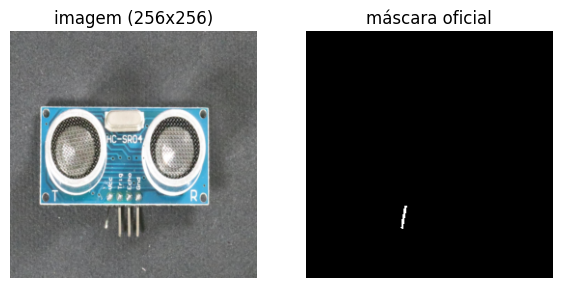

In [2]:
# ---- 2. Olhando os dados ---------------------------------------------------
import matplotlib.pyplot as plt

ds_exemplo = U.AnomalyDataset(RAIZ, "visa", "pcb1", split="test")
print(len(U.listar_amostras(RAIZ, "visa", "pcb1", "train")), "normais de treino,",
      len(U.listar_amostras(RAIZ, "visa", "pcb1", "val")), "de validação,",
      len(ds_exemplo), "de teste")
anomalas = [i for i, a in enumerate(ds_exemplo.amostras) if a.rotulo == 1]
item = ds_exemplo[anomalas[0]]
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(U.desnormalizar(item["image"])); ax[0].set_title("imagem (256x256)")
ax[1].imshow(item["mask"][0], cmap="gray"); ax[1].set_title("máscara oficial")
for a in ax:
    a.axis("off")
plt.show()

In [3]:
# ---- 3. Baseline: ResNet-18 congelada + distância à média por posição -----
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader

DEV = "cuda" if torch.cuda.is_available() else "cpu"
WORKERS = int(os.environ.get("TP1_WORKERS", 2))   # o Colab gratuito tem 2 CPUs
U.fixar_semente(42)


class ExtratorResNet18(torch.nn.Module):
    """Features de layer2 (28x28 -> 32x32 com entrada 256) + layer3 reamostrada."""

    def __init__(self):
        super().__init__()
        r = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        self.base = torch.nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1)
        self.layer2, self.layer3 = r.layer2, r.layer3

    def forward(self, x):
        f2 = self.layer2(self.base(x))
        f3 = F.interpolate(self.layer3(f2), size=f2.shape[-2:], mode="bilinear",
                           align_corners=False)
        return F.avg_pool2d(torch.cat([f2, f3], 1), 3, 1, 1)   # (B, 384, 32, 32)


modelo = ExtratorResNet18().to(DEV).eval()
transform = U.transformacao_padrao(256)


@torch.no_grad()
def media_por_posicao(dataset, categoria):
    """Média das features normais de treino em cada posição: (384, 32, 32)."""
    ds = U.AnomalyDataset(RAIZ, dataset, categoria, split="train", transform=transform)
    soma, n = 0.0, 0
    for b in DataLoader(ds, batch_size=32, num_workers=WORKERS):
        f = modelo(b["image"].to(DEV))
        soma = soma + f.sum(dim=0)
        n += f.shape[0]
    return soma / n


@torch.no_grad()
def pontuar(dataset, categoria, mu):
    ds = U.AnomalyDataset(RAIZ, dataset, categoria, split="test", transform=transform)
    rot, esc, masc, mapas = [], [], [], []
    for b in DataLoader(ds, batch_size=32, num_workers=WORKERS):
        f = modelo(b["image"].to(DEV))
        m = ((f - mu[None]) ** 2).sum(1)                     # (B, 32, 32)
        mapas.append(U.mapa_para_eval(m.cpu()))              # (B, 256, 256)
        esc.append(m.flatten(1).amax(1).cpu().numpy())       # escore = máximo do mapa
        rot.append(b["label"].numpy())
        masc.append(b["mask"][:, 0].numpy().astype(np.uint8))
    return (np.concatenate(rot), np.concatenate(esc),
            np.concatenate(masc), np.concatenate(mapas))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


Categoria       | Treino | Val  | Teste (N/A) | Tam. Médio Defeito (%)
-----------------------------------------------------------------
--- PCBs ---
pcb1            | 814    | 90   | 100  / 100  | 0.93%
pcb2            | 811    | 90   | 100  / 100  | 0.41%
pcb3            | 815    | 90   | 101  / 100  | 0.51%
pcb4            | 814    | 90   | 101  / 100  | 1.32%

--- Múltiplas instâncias ---
candle          | 810    | 90   | 100  / 100  | 0.27%
capsules        | 488    | 54   | 60   / 100  | 0.54%
macaroni1       | 810    | 90   | 100  / 100  | 0.07%
macaroni2       | 810    | 90   | 100  / 100  | 0.06%

--- Objetos únicos ---
cashew          | 405    | 45   | 50   / 100  | 1.69%
chewinggum      | 408    | 45   | 50   / 100  | 0.85%
fryum           | 405    | 45   | 50   / 100  | 3.46%
pipe_fryum      | 405    | 45   | 50   / 100  | 1.87%



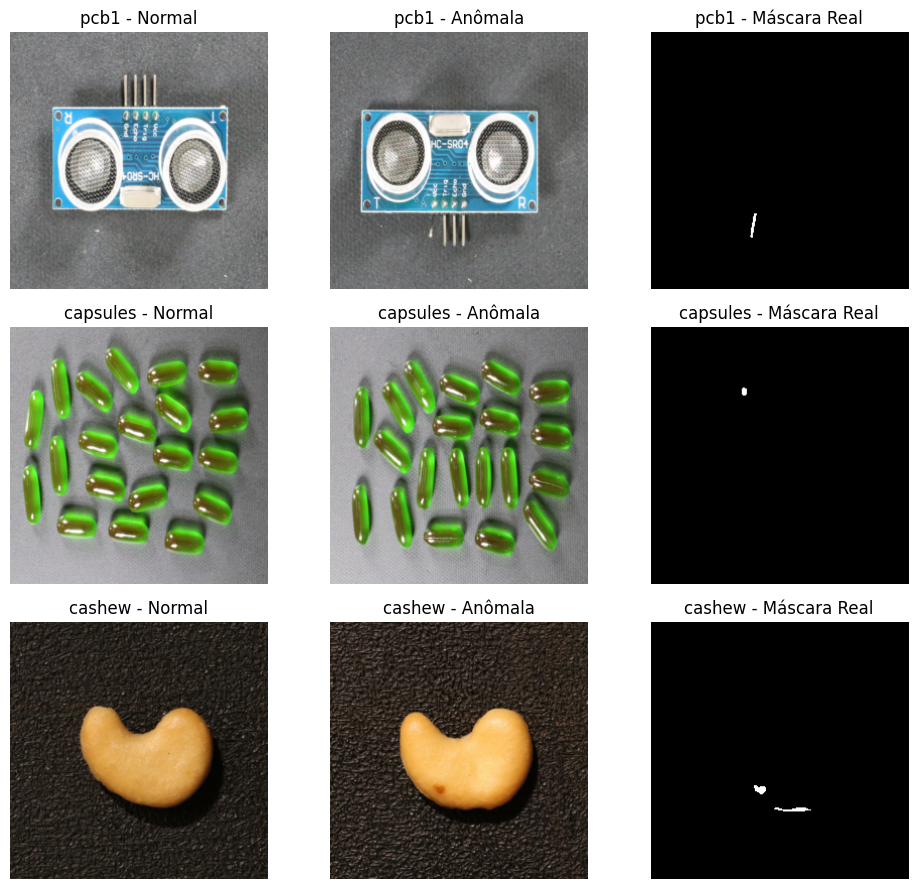

In [6]:
# 1. Agrupamento das categorias do VisA
grupos_visa = {
    "PCBs": ["pcb1", "pcb2", "pcb3", "pcb4"],
    "Múltiplas instâncias": ["candle", "capsules", "macaroni1", "macaroni2"],
    "Objetos únicos": ["cashew", "chewinggum", "fryum", "pipe_fryum"]
}

# 2 e 3. Contagem por split e medição do tamanho dos defeitos
print(f"{'Categoria':<15} | {'Treino':<6} | {'Val':<4} | {'Teste (N/A)':<11} | {'Tam. Médio Defeito (%)'}")
print("-" * 65)

transformacao = U.transformacao_padrao(256)

for grupo, categorias in grupos_visa.items():
    print(f"--- {grupo} ---")
    for cat in categorias:
        treino = U.listar_amostras(RAIZ, "visa", cat, "train")
        val = U.listar_amostras(RAIZ, "visa", cat, "val")
        teste = U.listar_amostras(RAIZ, "visa", cat, "test")

        teste_normais = sum(1 for a in teste if a.rotulo == 0)
        teste_anomalas = sum(1 for a in teste if a.rotulo == 1)

        # Carregando as máscaras para calcular a fração de pixels defeituosos
        ds_teste = U.AnomalyDataset(RAIZ, "visa", cat, split="test", transform=transformacao)
        fracoes_defeito = []

        for item in ds_teste:
            if item["label"] == 1:
                mascara = item["mask"][0].numpy()
                fracao = mascara.sum() / mascara.size
                fracoes_defeito.append(fracao * 100)

        media_tamanho = np.mean(fracoes_defeito) if fracoes_defeito else 0.0

        print(f"{cat:<15} | {len(treino):<6} | {len(val):<4} | {teste_normais:<4} / {teste_anomalas:<4} | {media_tamanho:.2f}%")
    print()

# 4. Plotagem de exemplos visuais (1 categoria por grupo para não poluir o notebook)
categorias_plot = ["pcb1", "capsules", "cashew"]
fig, axes = plt.subplots(len(categorias_plot), 3, figsize=(10, 3 * len(categorias_plot)))

for idx, cat in enumerate(categorias_plot):
    ds_teste = U.AnomalyDataset(RAIZ, "visa", cat, split="test", transform=transformacao)

    # Encontra o primeiro exemplo normal e o primeiro anômalo
    idx_normal = next(i for i, d in enumerate(ds_teste) if d["label"] == 0)
    idx_anom = next(i for i, d in enumerate(ds_teste) if d["label"] == 1)

    # Desnormaliza a imagem RGB para exibição correta com matplotlib
    img_normal = U.desnormalizar(ds_teste[idx_normal]["image"])
    img_anom = U.desnormalizar(ds_teste[idx_anom]["image"])
    mascara = ds_teste[idx_anom]["mask"][0].numpy()

    axes[idx, 0].imshow(img_normal)
    axes[idx, 0].set_title(f"{cat} - Normal")
    axes[idx, 0].axis("off")

    axes[idx, 1].imshow(img_anom)
    axes[idx, 1].set_title(f"{cat} - Anômala")
    axes[idx, 1].axis("off")

    axes[idx, 2].imshow(mascara, cmap="gray")
    axes[idx, 2].set_title(f"{cat} - Máscara Real")
    axes[idx, 2].axis("off")

plt.tight_layout()
plt.show()